In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("Churn Modeling.csv")

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.shape


(10000, 14)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [5]:
df.describe()


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [6]:
df.isnull().sum()


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [7]:
df.duplicated().sum()


np.int64(0)

In [8]:
df['Exited'].value_counts()


Exited
0    7963
1    2037
Name: count, dtype: int64

In [9]:
df['Exited'].value_counts(normalize=True) * 100


Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

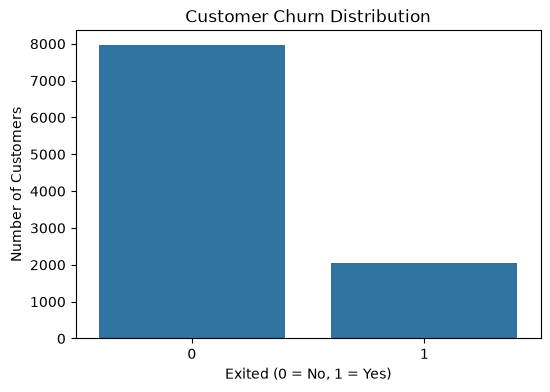

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Exited')

plt.title('Customer Churn Distribution')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

plt.show()


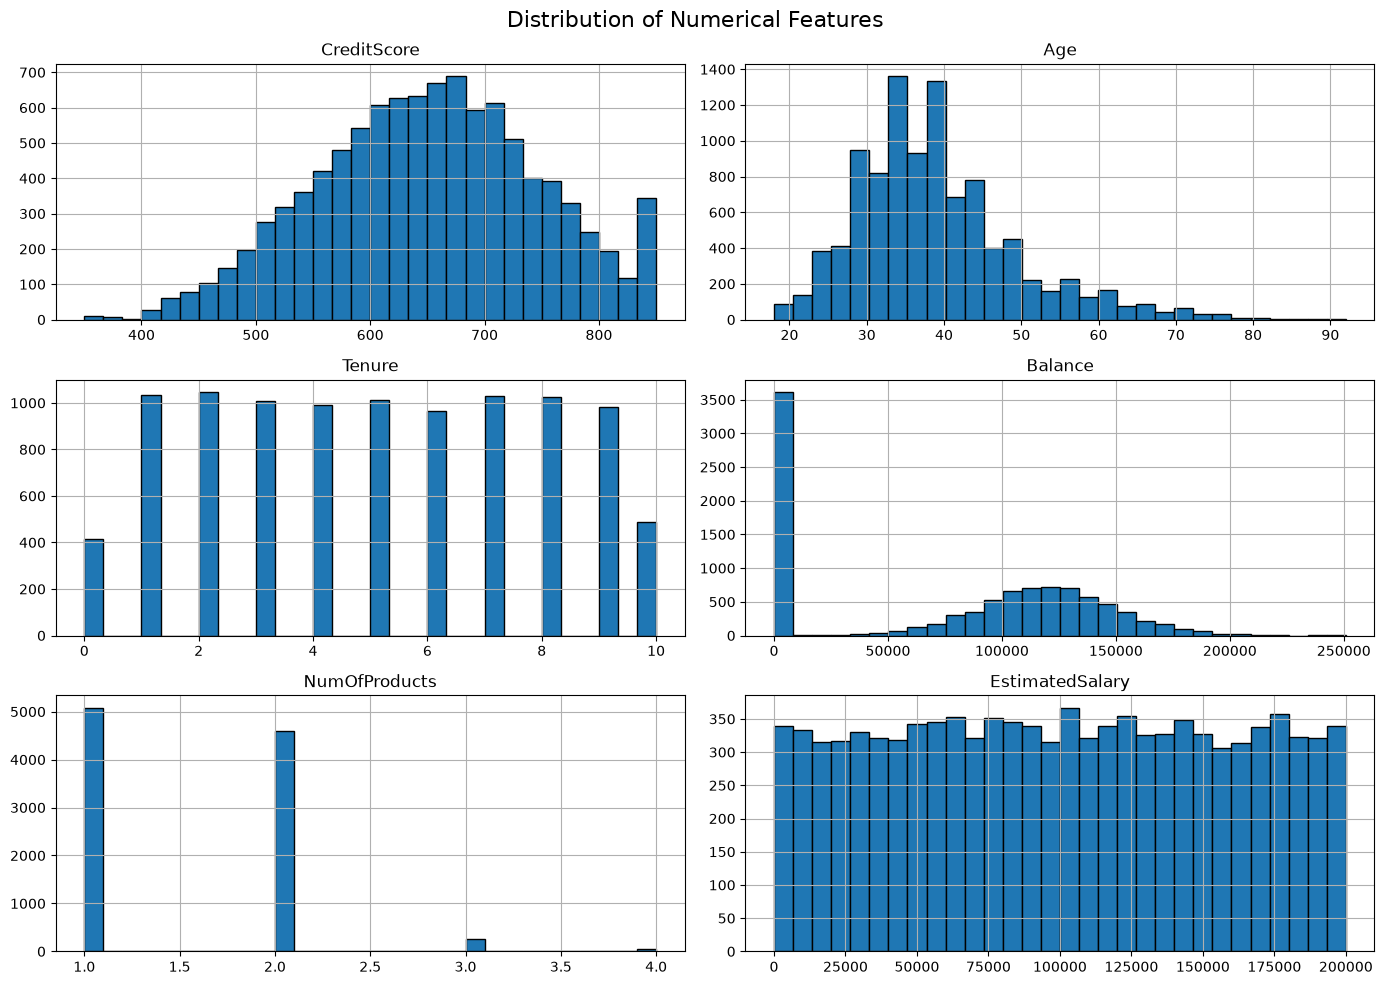

In [11]:
num_cols = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary'
]

df[num_cols].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()


In [12]:
df[num_cols].skew()

CreditScore       -0.071607
Age                1.011320
Tenure             0.010991
Balance           -0.141109
NumOfProducts      0.745568
EstimatedSalary    0.002085
dtype: float64

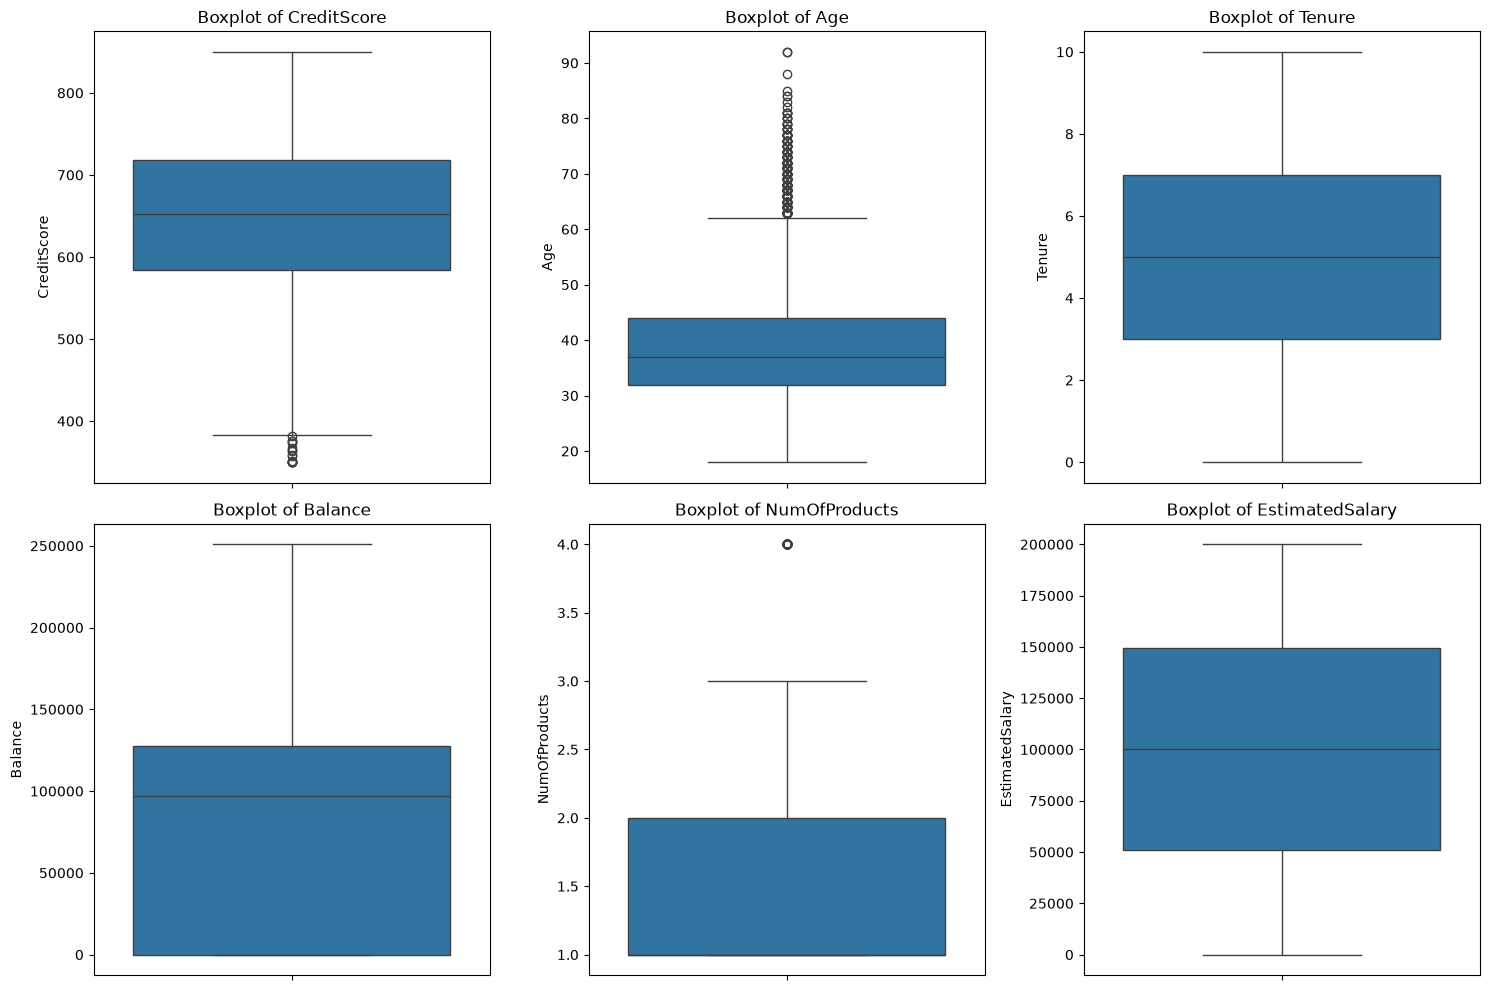

In [13]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

Outlier Analysis – Observations

Boxplots were used to identify potential outliers in numerical features.

CreditScore contains a few lower-end outliers.

Age contains several upper-end outliers, primarily among older customers.

NumOfProducts contains rare observations with four banking products.

Tenure, Balance and EstimatedSalary do not show significant outliers based on the IQR method.

The detected outliers appear to represent plausible customer characteristics rather than obvious data errors.

Therefore, no outlier removal or capping is performed at this stage.

All observations are retained for baseline ANN model development.

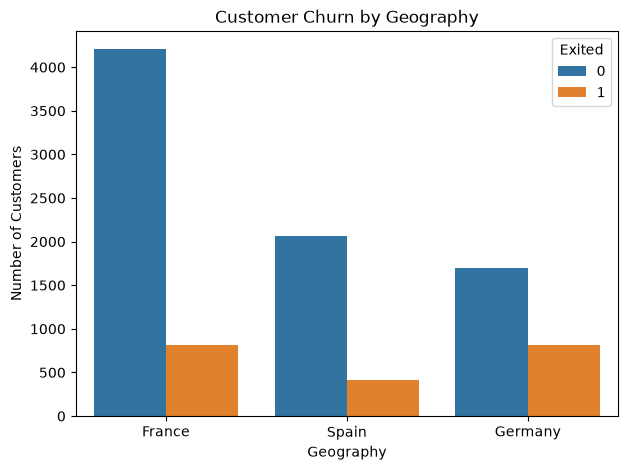

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Geography', hue='Exited')

plt.title('Customer Churn by Geography')
plt.xlabel('Geography')
plt.ylabel('Number of Customers')
plt.legend(title='Exited')

plt.show()


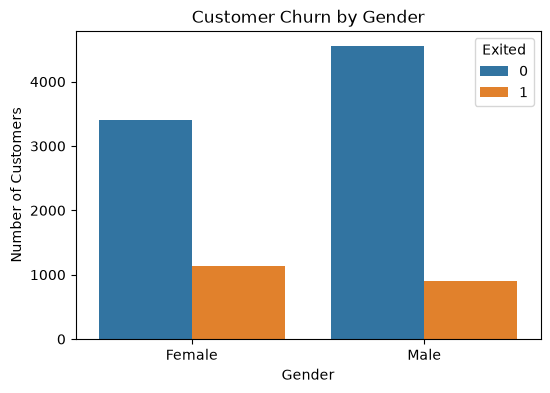

In [15]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Gender', hue='Exited')

plt.title('Customer Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.legend(title='Exited')

plt.show()


Germany appears to have the highest churn rate despite having fewer customers than France.

Gender may be associated with customer churn, although the graph alone does not establish causation.

Geography vs Churn

France has the largest customer base, followed by Germany and Spain.
Germany exhibits a comparatively higher proportion of churned customers.
Geography appears to be associated with customer churn and may be an important predictive feature.

Gender vs Churn

The dataset contains more male customers than female customers.
Female customers appear to have a higher churn rate compared to male customers.
Gender may contribute to churn prediction and will be included as a categorical feature during model development.

In [16]:
print("Churn Rate by Geography:")
print(
    (df.groupby('Geography')['Exited'].mean() * 100).round(2)
)

print("\nChurn Rate by Gender:")
print(
    (df.groupby('Gender')['Exited'].mean() * 100).round(2)
)

Churn Rate by Geography:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64

Churn Rate by Gender:
Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


Churn Analysis by Geography and Gender

Germany has the highest customer churn rate (32.44%), followed by Spain (16.67%) and France (16.15%).

German customers are approximately twice as likely to churn as customers in France or Spain within this dataset.

Female customers have a higher churn rate (25.07%) compared to male customers (16.46%).

Geography and Gender show an association with customer churn and may be useful predictors for the ANN model.

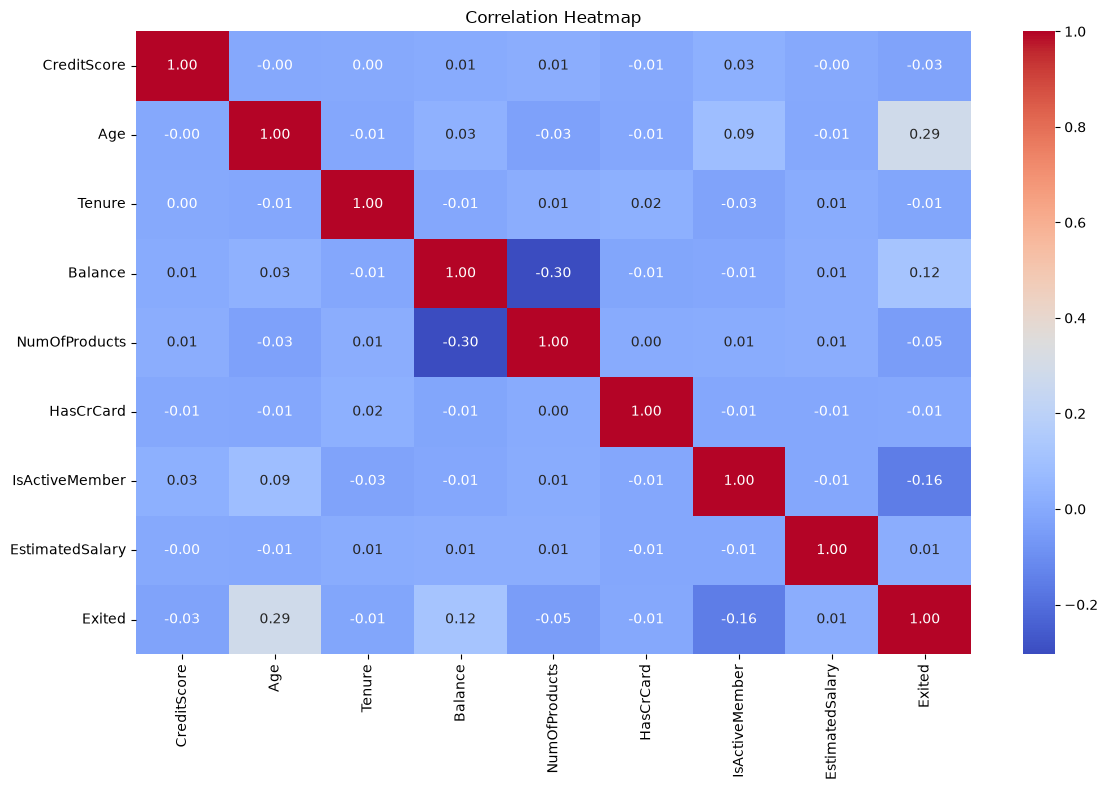

In [17]:
plt.figure(figsize=(12, 8))

corr_matrix = df.select_dtypes(include=['number']).drop(
    columns=['RowNumber', 'CustomerId']
).corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

Age has the strongest positive correlation with customer churn (0.29).

IsActiveMember has a negative correlation with churn (-0.16), indicating that active customers tend to have lower churn rates.

Balance shows a weak positive correlation with churn (0.12).

CreditScore, Tenure, HasCrCard, NumOfProducts and EstimatedSalary exhibit weak or negligible linear correlations with the target variable.

Balance and NumOfProducts show a moderate negative correlation (-0.30).

No severe multicollinearity is observed among the numerical predictors based on pairwise correlations.

All relevant predictive features will initially be retained because ANN models can capture nonlinear relationships that are not reflected in Pearson correlation coefficients.

In [18]:
X = df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname', 'Exited']
)

y = df['Exited']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X.head()


X Shape: (10000, 10)
y Shape: (10000,)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)


X_train Shape: (8000, 10)
X_test Shape: (2000, 10)
y_train Shape: (8000,)
y_test Shape: (2000,)


In [20]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore'
)

categorical_cols = ['Geography', 'Gender']

# Fit encoder on training data
X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

# Transform testing data
X_test_encoded = encoder.transform(
    X_test[categorical_cols]
)

print("Encoded Training Shape:", X_train_encoded.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)

print("Encoded Feature Names:")
print(encoder.get_feature_names_out(categorical_cols))


Encoded Training Shape: (8000, 3)
Encoded Testing Shape: (2000, 3)
Encoded Feature Names:
['Geography_Germany' 'Geography_Spain' 'Gender_Male']


In [21]:
# Drop original categorical columns
X_train_num = X_train.drop(columns=categorical_cols)
X_test_num = X_test.drop(columns=categorical_cols)

# Convert encoded arrays into DataFrames
encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train_cat = pd.DataFrame(
    X_train_encoded,
    columns=encoded_cols,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_encoded,
    columns=encoded_cols,
    index=X_test.index
)

# Combine numerical and encoded features
X_train_final = pd.concat(
    [X_train_num, X_train_cat], axis=1
)

X_test_final = pd.concat(
    [X_test_num, X_test_cat], axis=1
)

print("Training Shape:", X_train_final.shape)
print("Testing Shape:", X_test_final.shape)

X_train_final.head()


Training Shape: (8000, 11)
Testing Shape: (2000, 11)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
2151,753,57,7,0.00,1,1,0,159475.08,0.0,0.0,1.0
8392,739,32,3,102128.27,1,1,0,63981.37,1.0,0.0,1.0
5006,755,37,0,113865.23,2,1,1,117396.25,1.0,0.0,0.0
4117,561,37,5,0.00,2,1,0,83093.25,0.0,0.0,1.0
7182,692,49,6,110540.43,2,0,1,107472.99,1.0,0.0,1.0


In [22]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train, y_val = train_test_split(
    X_train_final,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Shape:", X_train_final.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test_final.shape)

print("y_train Shape:", y_train.shape)
print("y_val Shape:", y_val.shape)
print("y_test Shape:", y_test.shape)


Training Shape: (6400, 11)
Validation Shape: (1600, 11)
Testing Shape: (2000, 11)
y_train Shape: (6400,)
y_val Shape: (1600,)
y_test Shape: (2000,)


The dataset is divided into training (64%), validation (16%) and testing (20%) subsets.

Stratified sampling is applied to preserve the churn distribution.

The training dataset will be used to train the ANN model.

The validation dataset will be used for hyperparameter tuning, early stopping and model selection.

The testing dataset will be reserved for final evaluation of the selected model.

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scale_cols = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary'
]

# Create copies
X_train_scaled = X_train_final.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test_final.copy()

# Fit only on training data
X_train_scaled[scale_cols] = scaler.fit_transform(
    X_train_final[scale_cols]
)

# Transform validation and testing data
X_val_scaled[scale_cols] = scaler.transform(
    X_val[scale_cols]
)

X_test_scaled[scale_cols] = scaler.transform(
    X_test_final[scale_cols]
)

print("Training Shape:", X_train_scaled.shape)
print("Validation Shape:", X_val_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

X_train_scaled.head()


Training Shape: (6400, 11)
Validation Shape: (1600, 11)
Testing Shape: (2000, 11)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
3006,0.988678,0.572685,-1.384980,0.610704,-0.909878,1,0,1.566070,0.0,0.0,0.0
5735,-0.683985,0.477619,-0.355056,-1.237347,0.804346,0,1,0.036348,0.0,1.0,0.0
5652,0.410474,-0.948376,1.361485,-1.237347,0.804346,0,0,1.745403,0.0,0.0,0.0
26,1.081604,-0.282911,-1.041672,0.962063,-0.909878,1,1,1.228816,1.0,0.0,1.0
3596,-0.085130,-0.282911,-1.728288,1.144427,-0.909878,0,0,-0.764748,0.0,0.0,1.0


StandardScaler is applied to standardize the continuous numerical features.

The scaler is fitted only on the training dataset to prevent data leakage.

The same fitted scaler is used to transform the validation and testing datasets.

Binary and one-hot encoded features are retained in their original 0/1 format.

Feature scaling helps improve numerical stability and optimization during ANN training.

In [24]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [25]:
import sys

print(sys.executable)
print(sys.version)


c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\python.exe
3.12.0 | packaged by Anaconda, Inc. | (main, Oct  2 2023, 17:20:38) [MSC v.1916 64 bit (AMD64)]


In [26]:
import tensorflow as tf

print(tf.__version__)


2.21.0


In [27]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input


In [28]:
ann_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

Baseline ANN Architecture – Observations

The ANN consists of three hidden layers with 64, 32 and 16 neurons.

ReLU activation is used in the hidden layers, while sigmoid activation is used in the output layer for binary classification.

The network contains 3,393 trainable parameters.


In [29]:
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [30]:
history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8041 - loss: 0.4532 - val_accuracy: 0.8250 - val_loss: 0.4160
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8428 - loss: 0.3829 - val_accuracy: 0.8444 - val_loss: 0.3785
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8528 - loss: 0.3541 - val_accuracy: 0.8519 - val_loss: 0.3618
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8605 - loss: 0.3433 - val_accuracy: 0.8544 - val_loss: 0.3566
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8598 - loss: 0.3377 - val_accuracy: 0.8562 - val_loss: 0.3554
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8619 - loss: 0.3326 - val_accuracy: 0.8512 - val_loss: 0.3549
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8630 - loss: 0.3274 - val_accuracy: 0.8556 - val_loss: 0.3539
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8616 - loss: 0.3264 - val_accuracy: 0.

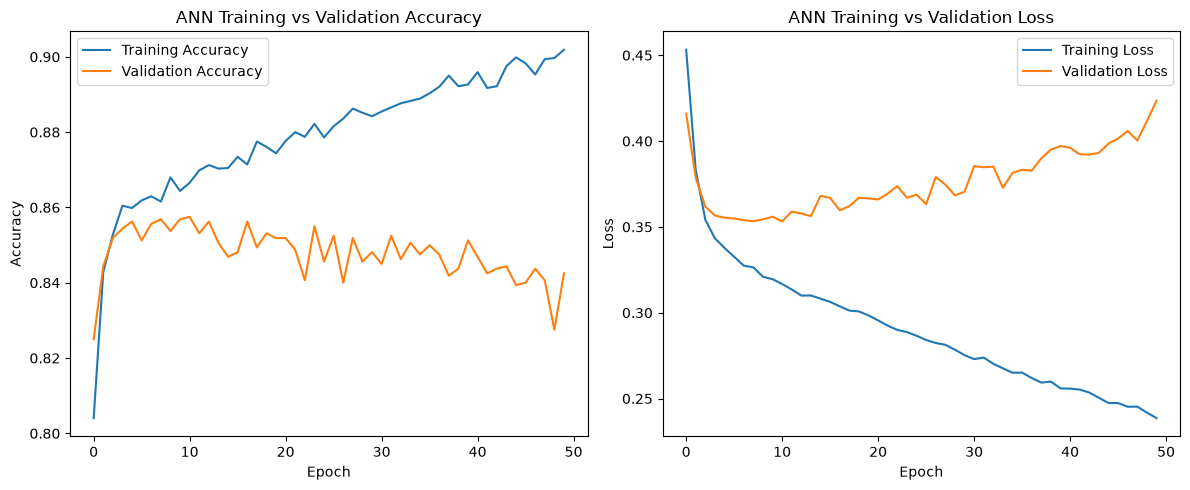

In [31]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('ANN Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('ANN Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


Baseline ANN Model – Performance Observations

The baseline ANN achieved approximately 90% training accuracy and 84% validation accuracy after 50 epochs.

Training accuracy increased consistently, while validation accuracy fluctuated and gradually declined.

Training loss decreased continuously, whereas validation loss started increasing after the initial epochs.

The widening gap between training and validation performance indicates overfitting.

To improve generalization, dropout regularization and early stopping will be implemented in the next model.

ModelCheckpoint will also be used to save the best-performing model based on validation loss.

Build ANN with Dropout

In [32]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

ann_dropout = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

ann_dropout.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

A second ANN model is developed using the same architecture as the baseline model.

Dropout rates of 0.3 and 0.2 are introduced after the first and second hidden layers, respectively.

Dropout randomly deactivates selected neuron outputs during training to reduce overfitting.

The model contains 3,393 trainable parameters.

Early stopping and ModelCheckpoint will be used to improve training efficiency and preserve the best-performing model.

In [ ]:
ann_dropout.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [34]:
#configure Early Stopping and ModelCheckpoint
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    filepath='best_ann_dropout.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

checkpoint_each_epoch = ModelCheckpoint(
    filepath='ann_epoch_{epoch:02d}.weights.h5',
    save_weights_only=True,
    save_best_only=False,
    verbose=0
)


In [35]:
history_dropout = ann_dropout.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[
        early_stopping,
        checkpoint,
        checkpoint_each_epoch
    ],
    verbose=1
)


Epoch 1/100
180/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7543 - loss: 0.5194
Epoch 1: val_loss improved from None to 0.43702, saving model to best_ann_dropout.keras

Epoch 1: finished saving model to best_ann_dropout.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7613 - loss: 0.5097 - val_accuracy: 0.8019 - val_loss: 0.4370
Epoch 2/100
183/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8127 - loss: 0.4338
Epoch 2: val_loss improved from 0.43702 to 0.41150, saving model to best_ann_dropout.keras

Epoch 2: finished saving model to best_ann_dropout.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8148 - loss: 0.4285 - val_accuracy: 0.8231 - val_loss: 0.4115
Epoch 3/100
197/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8290 - loss: 0.4069
Epoch 3: val_loss improved from 0.41150 to 0.38724, saving model to best_ann_dropout.keras

Epoch 3: finished saving model to best_ann_dropout.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8286 -

In [36]:
print(
    "Best Validation Accuracy:",
    round(max(history_dropout.history['val_accuracy']), 4)
)

print(
    "Best Validation Loss:",
    round(min(history_dropout.history['val_loss']), 4)
)

print(
    "Epochs Completed:",
    len(history_dropout.history['loss'])
)


Best Validation Accuracy: 0.8606
Best Validation Loss: 0.3442
Epochs Completed: 25


The ANN achieved a maximum validation accuracy of 86.06% and a minimum validation loss of 0.3442.

Early stopping terminated training after 25 epochs, preventing unnecessary training for the full 100 epochs.

ModelCheckpoint was implemented to preserve the best model based on validation loss.

Dropout regularization was introduced to reduce overfitting and improve generalization.

Further analysis of the training and validation curves is required to assess the effectiveness of regularization.

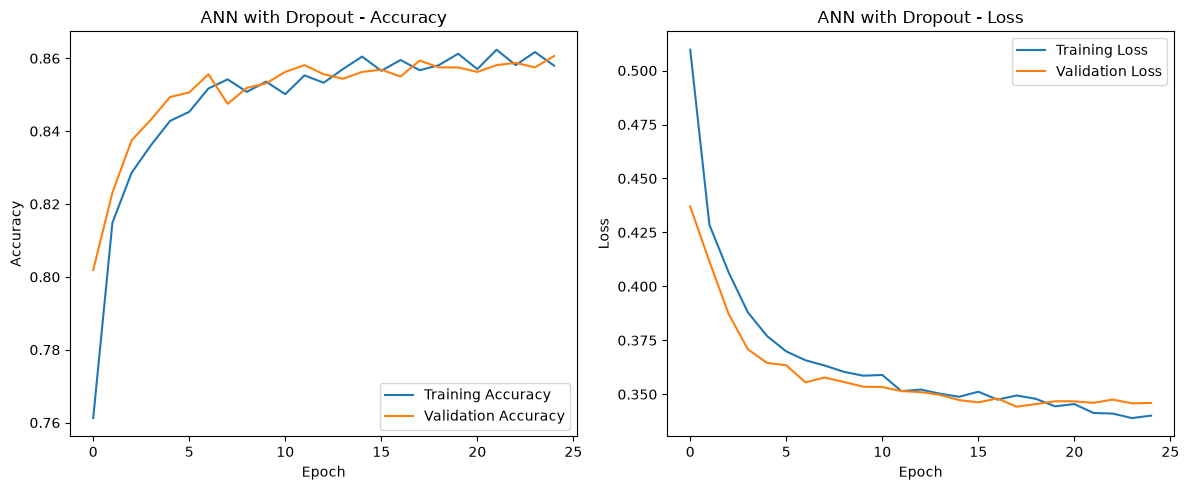

In [37]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_dropout.history['accuracy'],
         label='Training Accuracy')
plt.plot(history_dropout.history['val_accuracy'],
         label='Validation Accuracy')
plt.title('ANN with Dropout - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_dropout.history['loss'],
         label='Training Loss')
plt.plot(history_dropout.history['val_loss'],
         label='Validation Loss')
plt.title('ANN with Dropout - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


The baseline ANN exhibited overfitting, with training accuracy increasing while validation accuracy stagnated and validation loss increased.

The ANN with dropout achieved a maximum validation accuracy of 86.06% and a minimum validation loss of 0.3442.

Training and validation accuracy remained closely aligned, indicating improved generalization.

Dropout regularization helped reduce the gap between training and validation performance.

Early stopping terminated training after 25 epochs, preventing unnecessary additional training.

The dropout ANN demonstrated better validation learning behavior than the baseline ANN and will be compared with the hyperparameter-tuned model.

In [38]:
import keras_tuner as kt

print("KerasTuner Version:", kt.__version__)

KerasTuner Version: 1.4.8


In [39]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam, RMSprop

def build_model(hp):

    model = Sequential()
    model.add(Input(shape=(X_train_scaled.shape[1],)))

    # Tune number of hidden layers
    for i in range(hp.Int('num_layers', 1, 4)):

        # Tune neurons
        units = hp.Choice(
            f'units_{i}',
            values=[16, 32, 64, 128]
        )

        # Tune activation function
        activation = hp.Choice(
            f'activation_{i}',
            values=['relu', 'tanh']
        )

        model.add(Dense(units, activation=activation))

        # Tune dropout
        dropout_rate = hp.Choice(
            f'dropout_{i}',
            values=[0.0, 0.2, 0.3, 0.4]
        )

        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    # Output layer
    model.add(Dense(1, activation='sigmoid'))

    # Tune optimizer and learning rate
    optimizer_name = hp.Choice(
        'optimizer',
        values=['adam', 'rmsprop']
    )

    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.001, 0.0001]
    )

    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


KerasTuner is used to optimize the ANN architecture and training hyperparameters.

The search space includes 1–4 hidden layers, different neuron counts, activation functions, dropout rates, optimizers and learning rates.

Binary crossentropy is retained as the loss function for binary churn classification.

The tuning process will identify the configuration with the best validation performance.

The optimized model will be compared with the baseline ANN and dropout ANN before final model selection.

In [40]:
import keras_tuner as kt

tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective='val_loss',
    max_trials=15,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='bank_churn_ann',
    overwrite=True,
    seed=42
)

tuner.search_space_summary()


Search space summary
Default search space size: 6
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 4, 'step': 1, 'sampling': 'linear'}
units_0 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128], 'ordered': True}
activation_0 (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
dropout_0 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.2, 0.3, 0.4], 'ordered': True}
optimizer (Choice)
{'default': 'adam', 'conditions': [], 'values': ['adam', 'rmsprop'], 'ordered': False}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0001], 'ordered': True}


In [41]:
from tensorflow.keras.callbacks import EarlyStopping

tuner_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

tuner.search(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[tuner_early_stopping],
    verbose=1
)

Trial 2 Complete [00h 00m 00s]

Best val_loss So Far: None
Total elapsed time: 00h 00m 00s

Search: Running Trial #3

Value             |Best Value So Far |Hyperparameter
4                 |3                 |num_layers
16                |16                |units_0
tanh              |relu              |activation_0
0                 |0.2               |dropout_0
rmsprop           |rmsprop           |optimizer
0.001             |0.001             |learning_rate



Traceback (most recent call last):
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\base_tuner.py", line 274, in _try_run_and_update_trial
    self._run_and_update_trial(trial, *fit_args, **fit_kwargs)
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\base_tuner.py", line 239, in _run_and_update_trial
    results = self.run_trial(trial, *fit_args, **fit_kwargs)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\tuner.py", line 309, in run_trial
    self._configure_tensorboard_dir(callbacks, trial, execution)
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\tuner.py", line 421, in _configure_tensorboard_dir
    from tensorboard

RuntimeError: Number of consecutive failures exceeded the limit of 3.
Traceback (most recent call last):
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\base_tuner.py", line 274, in _try_run_and_update_trial
    self._run_and_update_trial(trial, *fit_args, **fit_kwargs)
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\base_tuner.py", line 239, in _run_and_update_trial
    results = self.run_trial(trial, *fit_args, **fit_kwargs)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\tuner.py", line 309, in run_trial
    self._configure_tensorboard_dir(callbacks, trial, execution)
  File "c:\Users\Dell\Downloads\Deployment_ANN_Assignment_Bank_Customers_Churn\myenv\Lib\site-packages\keras_tuner\src\engine\t

In [42]:
import tensorboard

print("TensorBoard Version:", tensorboard.__version__)


TensorBoard Version: 2.21.0


In [43]:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective='val_loss',
    max_trials=15,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='bank_churn_ann',
    overwrite=True,
    seed=42
)

In [44]:
tuner.search(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)


Trial 15 Complete [00h 00m 36s]
val_loss: 0.38440266251564026

Best val_loss So Far: 0.341463178396225
Total elapsed time: 00h 08m 06s


In [45]:
tuner.results_summary(num_trials=5)


Results summary
Results in keras_tuner_results\bank_churn_ann
Showing 5 best trials
Objective(name="val_loss", direction="min")

Trial 11 summary
Hyperparameters:
num_layers: 3
units_0: 32
activation_0: tanh
dropout_0: 0.4
optimizer: adam
learning_rate: 0.001
units_1: 128
activation_1: relu
dropout_1: 0.0
units_2: 128
activation_2: tanh
dropout_2: 0.4
Score: 0.341463178396225

Trial 02 summary
Hyperparameters:
num_layers: 2
units_0: 32
activation_0: tanh
dropout_0: 0.2
optimizer: adam
learning_rate: 0.001
units_1: 16
activation_1: relu
dropout_1: 0.3
units_2: 64
activation_2: tanh
dropout_2: 0.2
Score: 0.3422074615955353

Trial 00 summary
Hyperparameters:
num_layers: 3
units_0: 16
activation_0: relu
dropout_0: 0.2
optimizer: rmsprop
learning_rate: 0.001
units_1: 16
activation_1: relu
dropout_1: 0.0
units_2: 16
activation_2: relu
dropout_2: 0.0
Score: 0.34872230887413025

Trial 04 summary
Hyperparameters:
num_layers: 3
units_0: 16
activation_0: tanh
dropout_0: 0.0
optimizer: adam
learni

In [46]:
# Extract best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

# Build optimized ANN
ann_tuned = tuner.hypermodel.build(best_hp)

# Display model architecture
ann_tuned.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,249 (83.00 KB)

 Trainable params: 21,249 (83.00 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
#Configure Early Stopping and ModelCheckpoint
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping_tuned = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

checkpoint_tuned = ModelCheckpoint(
    filepath='best_ann_tuned.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)


In [48]:
history_tuned = ann_tuned.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[
        early_stopping_tuned,
        checkpoint_tuned
    ],
    verbose=1
)


Epoch 1/100
181/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8040 - loss: 0.4546
Epoch 1: val_loss improved from None to 0.42483, saving model to best_ann_tuned.keras

Epoch 1: finished saving model to best_ann_tuned.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8036 - loss: 0.4568 - val_accuracy: 0.8112 - val_loss: 0.4248
Epoch 2/100
192/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8166 - loss: 0.4202
Epoch 2: val_loss improved from 0.42483 to 0.38307, saving model to best_ann_tuned.keras

Epoch 2: finished saving model to best_ann_tuned.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8175 - loss: 0.4195 - val_accuracy: 0.8481 - val_loss: 0.3831
Epoch 3/100
197/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8295 - loss: 0.3980
Epoch 3: val_loss improved from 0.38307 to 0.37102, saving model to best_ann_tuned.keras

Epoch 3: finished saving model to best_ann_tuned.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8280 - loss: 0.399

In [49]:
print("Best Validation Accuracy:",
      round(max(history_tuned.history['val_accuracy']), 4))

print("Best Validation Loss:",
      round(min(history_tuned.history['val_loss']), 4))

print("Epochs Completed:",
      len(history_tuned.history['loss']))


Best Validation Accuracy: 0.8631
Best Validation Loss: 0.3428
Epochs Completed: 33


In [51]:
#The tuned ANN achieved a 0.25 percentage-point increase in maximum validation accuracy over the Dropout ANN, with a slightly lower minimum validation loss.

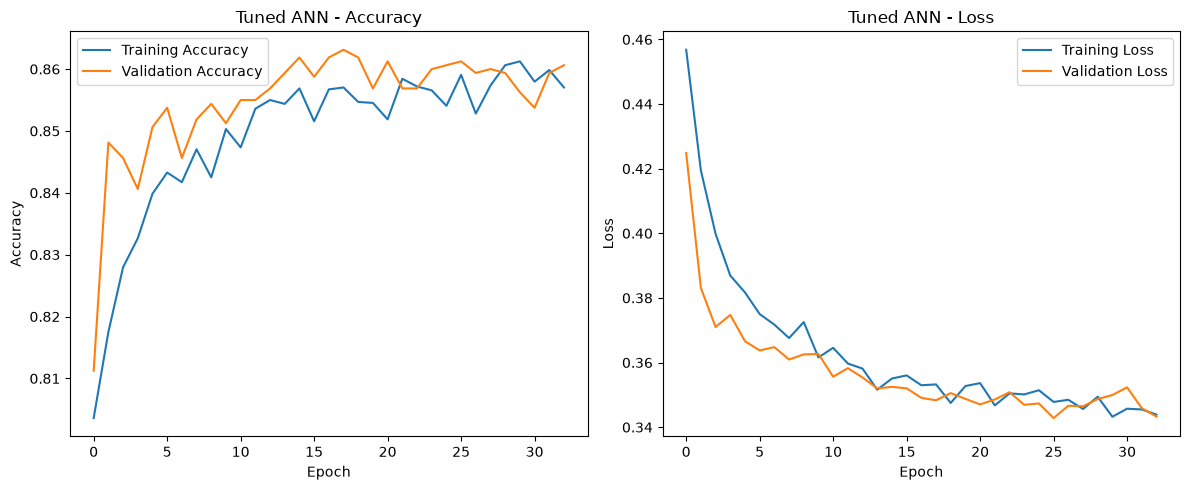

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['accuracy'],
         label='Training Accuracy')
plt.plot(history_tuned.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Tuned ANN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['loss'],
         label='Training Loss')
plt.plot(history_tuned.history['val_loss'],
         label='Validation Loss')

plt.title('Tuned ANN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Tuned ANN – Learning Curve Observations

Training and validation accuracy increased steadily and stabilized around 86%.

Training and validation loss decreased consistently and converged near 0.34.

The small gap between training and validation performance indicates limited overfitting.

Dropout regularization and early stopping helped control overfitting.

The tuned ANN achieved a maximum validation accuracy of 86.31% and minimum validation loss of 0.3428.

The tuned model demonstrated slightly better validation performance than the previous Dropout ANN and is a suitable candidate for final model selection.

In [53]:
import pandas as pd
from tensorflow.keras.models import load_model

# Load best saved models
best_dropout = load_model('best_ann_dropout.keras')
best_tuned = load_model('best_ann_tuned.keras')

# Evaluate on validation dataset
baseline_val = ann_model.evaluate(
    X_val_scaled, y_val, verbose=0
)

dropout_val = best_dropout.evaluate(
    X_val_scaled, y_val, verbose=0
)

tuned_val = best_tuned.evaluate(
    X_val_scaled, y_val, verbose=0
)

# Comparison table
comparison_df = pd.DataFrame({
    'Model': [
        'Baseline ANN',
        'ANN with Dropout',
        'KerasTuner Optimized ANN'
    ],
    'Validation Accuracy': [
        baseline_val[1],
        dropout_val[1],
        tuned_val[1]
    ],
    'Validation Loss': [
        baseline_val[0],
        dropout_val[0],
        tuned_val[0]
    ]
})

comparison_df = comparison_df.sort_values(
    by='Validation Loss'
)

comparison_df.round(4)


,Model,Validation Accuracy,Validation Loss
2,KerasTuner Optimized ANN,0.8612,0.3428
1,ANN with Dropout,0.8594,0.3442
0,Baseline ANN,0.8425,0.4235


The optimized ANN achieved the highest checkpoint validation accuracy of 86.12%.



It also achieved the lowest validation loss of 0.3428.



Compared with the baseline ANN, validation accuracy improved by 1.87 percentage points.



Dropout and early stopping substantially reduced the overfitting observed in the baseline model.



The tuned ANN is our selected candidate for final evaluation.

In [54]:
# Evaluate final optimized ANN on test data

test_loss, test_accuracy = best_tuned.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Loss:", round(test_loss, 4))


Test Accuracy: 0.865
Test Loss: 0.3351


In [55]:
# Predict churn probabilities
y_pred_prob = best_tuned.predict(X_test_scaled).ravel()

# Convert probabilities into binary predictions
y_pred = (y_pred_prob >= 0.5).astype(int)

print("Predicted Classes:", y_pred[:10])
print("Predicted Probabilities:", y_pred_prob[:10])

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Predicted Classes: [0 0 0 0 0 0 0 0 1 0]
Predicted Probabilities: [0.01577462 0.04783722 0.03570401 0.04785252 0.08509524 0.16905664
 0.03211903 0.16841215 0.74288946 0.03747037]


The KerasTuner Optimized ANN achieved a test accuracy of 86.50% and test loss of 0.3351.

Test accuracy was slightly higher than the validation accuracy of 86.12%.

The close validation and test performance suggests that the model generalizes reasonably well to unseen customer data.

The model generated churn probabilities using sigmoid activation, which were converted into binary predictions using a threshold of 0.5.

Further evaluation using a confusion matrix, precision, recall, F1-score and ROC-AUC is necessary to assess performance on the minority churn class.

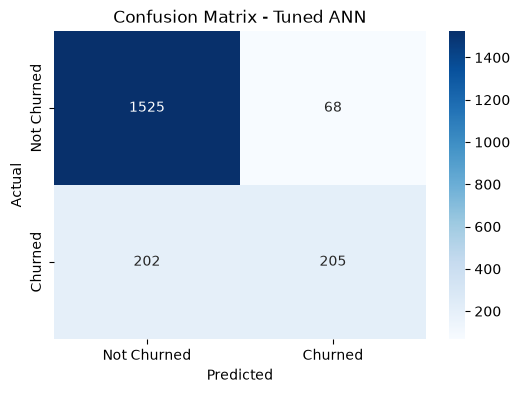

In [56]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churned', 'Churned'],
    yticklabels=['Not Churned', 'Churned']
)

plt.title('Confusion Matrix - Tuned ANN')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


The tuned ANN correctly classified 1,525 non-churned customers and 205 churned customers.

The model incorrectly classified 68 non-churned customers as churners and failed to identify 202 actual churners.

The overall test accuracy was 86.50%.

The model demonstrated strong performance in identifying customers who remained with the bank.

However, churn recall was approximately 50.37%, indicating that nearly half of the actual churners were not identified.

This limitation is important from a business perspective, as undetected churners represent missed customer retention opportunities.

Further evaluation using precision, recall, F1-score and ROC-AUC will provide a more comprehensive assessment of model performance.

In [57]:

from sklearn.metrics import classification_report

print("Classification Report - Tuned ANN")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Not Churned', 'Churned']
    )
)


Classification Report - Tuned ANN
              precision    recall  f1-score   support

 Not Churned       0.88      0.96      0.92      1593
     Churned       0.75      0.50      0.60       407

    accuracy                           0.86      2000
   macro avg       0.82      0.73      0.76      2000
weighted avg       0.86      0.86      0.85      2000



Classification Report – Tuned ANN Observations

The KerasTuner Optimized ANN achieved an overall test accuracy of 86.50%.

The model demonstrated strong performance in identifying non-churned customers, with a precision of 88%, recall of 96%, and F1-score of 92%.

For churned customers, the model achieved a precision of 75%, recall of 50%, and F1-score of 60%.

The lower recall for churned customers indicates that approximately half of the actual churners were not identified.

The class imbalance in the dataset may contribute to the difference in prediction performance between the two classes.

Although the model achieved good overall accuracy, improving churn recall could help the bank identify more at-risk customers and take proactive retention measures.

ROC-AUC Score: 0.8624


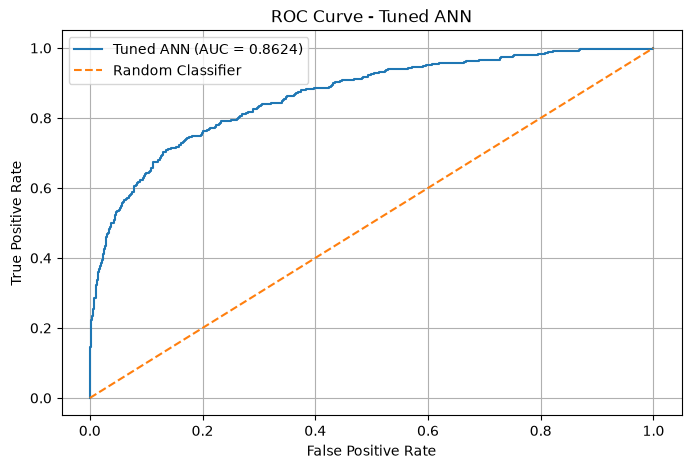

In [58]:
#ROC-AUC Score and ROC Curve
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, y_pred_prob)

print("ROC-AUC Score:", round(roc_auc, 4))

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

# Plot ROC curve
plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label=f'Tuned ANN (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned ANN')
plt.legend()
plt.grid(True)

plt.show()


The KerasTuner Optimized ANN achieved an ROC-AUC score of 0.8624.

The ROC curve lies significantly above the random classifier's diagonal line, indicating good classification performance.

The model demonstrates good ability to distinguish between churned and non-churned customers across different classification thresholds.

Despite achieving an overall test accuracy of 86.50%, churn recall remains approximately 50%, suggesting scope for improvement in identifying customers at risk of leaving.

Overall, the ROC-AUC results support the effectiveness of the tuned ANN for bank customer churn prediction.

In [59]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Predict probabilities on validation data
y_val_prob = best_tuned.predict(
    X_val_scaled,
    verbose=0
).ravel()

results = []

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_val_pred),
        'Recall': recall_score(y_val, y_val_pred),
        'F1-score': f1_score(y_val, y_val_pred)
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.round(4))


   Threshold  Precision  Recall  F1-score
0        0.3     0.6000  0.6534    0.6256
1        0.4     0.6898  0.5798    0.6300
2        0.5     0.7430  0.4877    0.5889
3        0.6     0.8397  0.4018    0.5436


Different classification thresholds were evaluated using the validation dataset to improve churn prediction performance.

The default threshold of 0.5 achieved a churn recall of 48.77% and F1-score of 58.89%.

Reducing the threshold to 0.4 increased churn recall to 57.98% and improved the F1-score to 63.00%.

The threshold of 0.4 provided the best balance between precision and recall among the evaluated thresholds.

Therefore, 0.4 was selected as the classification threshold based on validation F1-score, subject to final evaluation on the test dataset.

In [60]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Apply optimized threshold
optimal_threshold = 0.4

y_pred_optimized = (
    y_pred_prob >= optimal_threshold
).astype(int)

# Evaluate model
print("Test Accuracy:",
      round(accuracy_score(y_test, y_pred_optimized), 4))

print("\nClassification Report - Threshold 0.4")
print(classification_report(
    y_test,
    y_pred_optimized,
    target_names=['Not Churned', 'Churned']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_optimized))


Test Accuracy: 0.8585

Classification Report - Threshold 0.4
              precision    recall  f1-score   support

 Not Churned       0.90      0.93      0.91      1593
     Churned       0.68      0.57      0.62       407

    accuracy                           0.86      2000
   macro avg       0.79      0.75      0.77      2000
weighted avg       0.85      0.86      0.85      2000


Confusion Matrix:
[[1483  110]
 [ 173  234]]


The KerasTuner Optimized ANN achieved a test accuracy of 85.85% using a classification threshold of 0.4.

Churn recall improved from 50.37% to 57.49%, allowing the model to identify 29 additional churned customers.

The churn F1-score improved from approximately 60% to 62%.

Although overall accuracy decreased slightly, the model demonstrated better performance in identifying customers at risk of churn.

The threshold of 0.4 was selected based on validation F1-score and evaluated on unseen test data.

The optimized model can support customer retention strategies by identifying more potentially at-risk customers.

In [61]:
# Save final KerasTuner optimized ANN model

best_tuned.save("bank_churn_ann_model.keras")

print("Final ANN model saved successfully!")

Final ANN model saved successfully!


In [62]:
import joblib

# Save fitted encoder
joblib.dump(encoder, "encoder.pkl")

# Save fitted scaler
joblib.dump(scaler, "scaler.pkl")

# Save model feature order
joblib.dump(
    X_train_scaled.columns.tolist(),
    "feature_columns.pkl"
)

print("Encoder, scaler and feature columns saved successfully!")


Encoder, scaler and feature columns saved successfully!


In [63]:
import joblib

# Save the fitted StandardScaler
joblib.dump(scaler, 'scaler.pkl')

# Save the fitted OneHotEncoder
joblib.dump(encoder, 'encoder.pkl')

# Save the final feature column order
joblib.dump(
    X_train_scaled.columns.tolist(),
    'feature_columns.pkl'
)

print("All preprocessing files saved successfully!")


All preprocessing files saved successfully!
